
# AME 5052 — Applied Machine Learning Lab
## Question 1: Supervised Learning Algorithms
### Question 3: Performance Evaluation and Analysis

### Objectives
1. Implement Linear Regression and regularization techniques using Ridge and Lasso.
2. Implement Decision Tree classification using Gini impurity and entropy.
3. Implement Logistic Regression, the sigmoid function, decision boundaries and regularization.
4. Implement the K-Nearest Neighbors algorithm.
5. Implement the Gaussian Naive Bayes classifier.
6. Evaluate and compare the models using appropriate performance metrics.


Section 1 — Imports and dataset preparation


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score,
    RocCurveDisplay
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("All libraries imported successfully.")


All libraries imported successfully.


In [ ]:
#Cell 2: Load and split datasets
# Here we load two datasets: one for regression (diabetes) and 
# one for classification (breast cancer). We then split each dataset into training and testing sets.
#The datasets used in this code are:
#1. Diabetes dataset (for regression) (from sklearn.datasets.load_diabetes)
#2. Breast cancer dataset (for classification) (from sklearn.datasets.load_breast_cancer)

# ---------------- REGRESSION DATASET ----------------
diabetes = load_diabetes(as_frame=True)

X_reg = diabetes.data
y_reg = diabetes.target

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=RANDOM_STATE
)

# ---------------- CLASSIFICATION DATASET ----------------
cancer = load_breast_cancer(as_frame=True)

X_cls = cancer.data
y_cls = cancer.target

X_train, X_test, y_train, y_test = train_test_split(
    X_cls,
    y_cls,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_cls
)

print("REGRESSION DATASET")
print("Training samples:", X_reg_train.shape[0])
print("Testing samples:", X_reg_test.shape[0])
print("Features:", X_reg_train.shape[1])

print("\nCLASSIFICATION DATASET")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Features:", X_train.shape[1])

print("\nClass labels:", dict(enumerate(cancer.target_names)))


REGRESSION DATASET
Training samples: 353
Testing samples: 89
Features: 10

CLASSIFICATION DATASET
Training samples: 455
Testing samples: 114
Features: 30

Class labels: {0: np.str_('malignant'), 1: np.str_('benign')}


In [6]:
#Cell 3: Create reusable evaluation functions
#These functions help us avoid repeating evaluation code across every classifier.

def evaluate_regression(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }


def evaluate_classification(y_true, y_pred, model_name, y_prob=None):
    result = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0)
    }

    if y_prob is not None:
        result["ROC-AUC"] = roc_auc_score(y_true, y_prob)

    return result


def show_confusion_matrix(model, X, y, title):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X,
        y,
        display_labels=cancer.target_names
    )
    plt.title(title)
    plt.tight_layout()
    plt.show()


print("Evaluation functions defined successfully.")


Evaluation functions defined successfully.


Section 2 — Q1(a): Linear Regression, Ridge and Lasso


## Q1(a): Linear Regression, Ridge and Lasso

**Aim:** To implement Linear Regression and study the effects of L1 and L2 regularization using Lasso and Ridge regression.

**Theory:**
Linear Regression models the relationship between input features and a continuous target.

Ridge Regression applies L2 regularization, which penalizes the squared magnitude of coefficients. Lasso Regression applies L1 regularization, which penalizes the absolute magnitude of coefficients and can shrink some coefficients to zero.

**Metrics:** MAE, RMSE and R².

In [7]:
regression_models = {
    "Linear Regression": make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),
    "Ridge Regression": make_pipeline(
        StandardScaler(),
        Ridge(alpha=1.0)
    ),
    "Lasso Regression": make_pipeline(
        StandardScaler(),
        Lasso(alpha=0.1, max_iter=20000)
    )
}

regression_results = []
regression_predictions = {}

for name, model in regression_models.items():
    model.fit(X_reg_train, y_reg_train)

    predictions = model.predict(X_reg_test)
    regression_predictions[name] = predictions

    regression_results.append(
        evaluate_regression(y_reg_test, predictions, name)
    )

regression_results_df = pd.DataFrame(regression_results)

display(regression_results_df.round(3))


,Model,MAE,RMSE,R2
0,Linear Regression,42.794,53.853,0.453
1,Ridge Regression,42.812,53.777,0.454
2,Lasso Regression,42.805,53.709,0.456


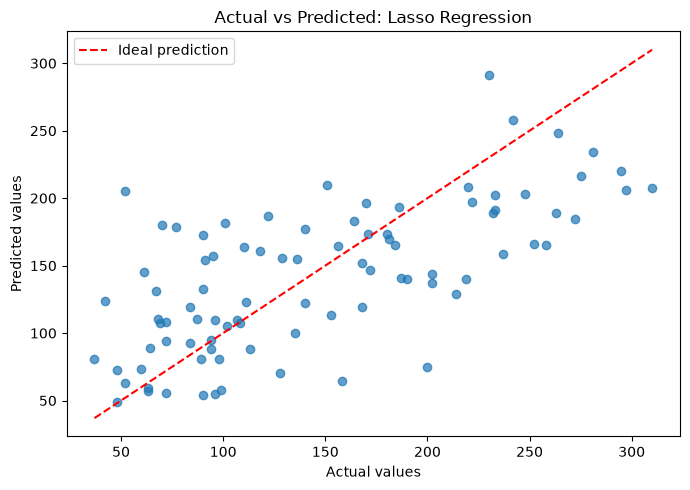

Best model by test RMSE: Lasso Regression


In [8]:

best_regression = regression_results_df.sort_values(
    "RMSE"
).iloc[0]["Model"]

best_predictions = regression_predictions[best_regression]

plt.figure(figsize=(7, 5))
plt.scatter(y_reg_test, best_predictions, alpha=0.7)

minimum = min(y_reg_test.min(), best_predictions.min())
maximum = max(y_reg_test.max(), best_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--",
    label="Ideal prediction"
)

plt.xlabel("Actual values")
plt.ylabel("Predicted values")
plt.title(f"Actual vs Predicted: {best_regression}")
plt.legend()
plt.tight_layout()
plt.show()

print("Best model by test RMSE:", best_regression)


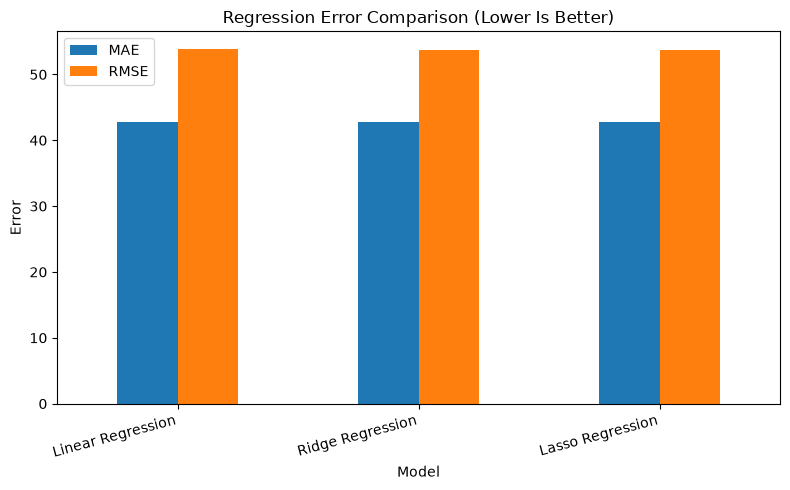

In [9]:

regression_results_df.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.ylabel("Error")
plt.title("Regression Error Comparison (Lower Is Better)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()



### Observation and Analysis

Linear Regression, Ridge Regression and Lasso Regression were implemented and evaluated using MAE, RMSE and R².

Linear Regression achieved the lowest MAE of 42.794. Ridge Regression achieved an RMSE of 53.777, while Lasso Regression achieved the lowest RMSE of 53.709 and the highest R² of 0.456.

The results indicate that regularization produced small improvements in RMSE and R² compared with ordinary Linear Regression. However, the differences between the models were marginal. Therefore, Lasso Regression performed best according to RMSE and R² on this particular test split, while Linear Regression performed best according to MAE.



## Q1(b): Decision Tree Classification

**Aim:** To implement Decision Tree classification using Gini impurity and entropy.

**Theory:**
A Decision Tree repeatedly splits the dataset into smaller groups using feature-based conditions.

Gini impurity measures the probability of incorrectly classifying an observation if it is labelled according to the class distribution in a node.

Entropy measures the uncertainty in a node. Information gain is the reduction in impurity after a split.

Gini impurity = 1 - sum(p_i²)

Entropy = -sum(p_i log₂(p_i))

Information Gain = Parent Impurity - Weighted Child Impurity


In [11]:
decision_tree_models = {}
decision_tree_results = []

for criterion in ["gini", "entropy"]:
    model = DecisionTreeClassifier(
        criterion=criterion,
        max_depth=4,
        random_state=RANDOM_STATE
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    decision_tree_models[criterion] = model

    decision_tree_results.append(
        evaluate_classification(
            y_test,
            predictions,
            f"Decision Tree ({criterion})"
        )
    )

decision_tree_results_df = pd.DataFrame(decision_tree_results)

display(decision_tree_results_df.round(3))


,Model,Accuracy,Precision,Recall,F1-score
0,Decision Tree (gini),0.939,0.958,0.944,0.951
1,Decision Tree (entropy),0.939,0.958,0.944,0.951


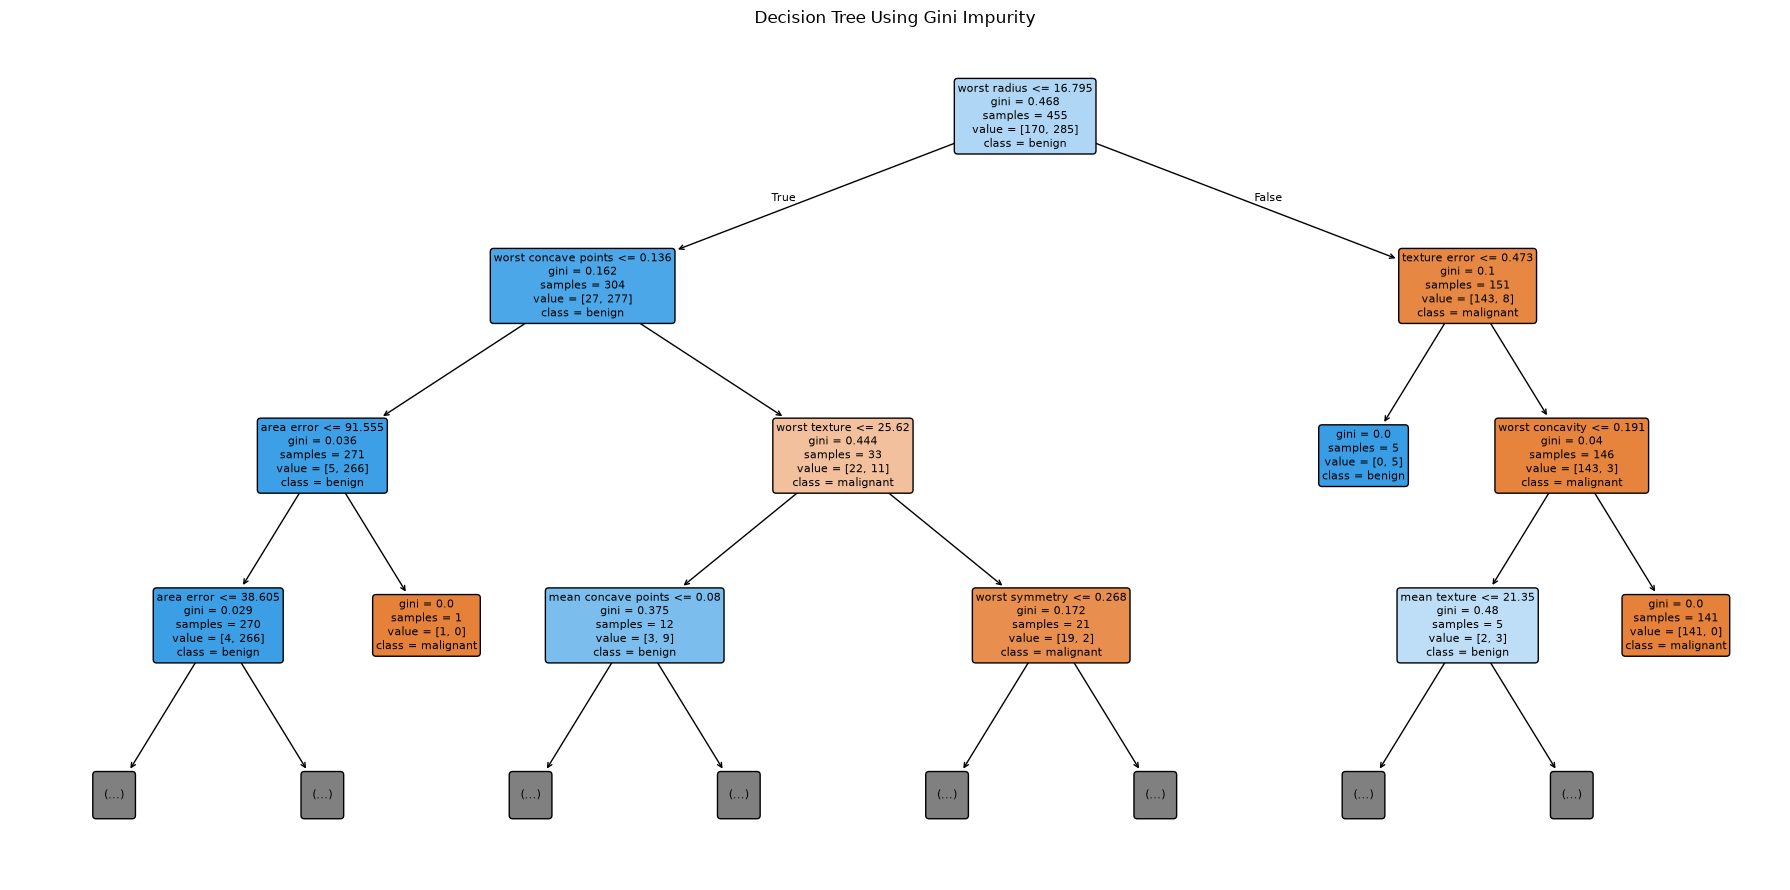

In [12]:

plt.figure(figsize=(18, 9))

plot_tree(
    decision_tree_models["gini"],
    feature_names=list(X_cls.columns),
    class_names=list(cancer.target_names),
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree Using Gini Impurity")
plt.tight_layout()
plt.show()


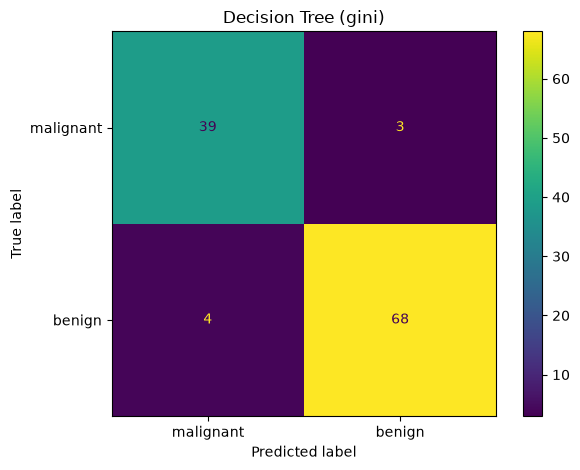

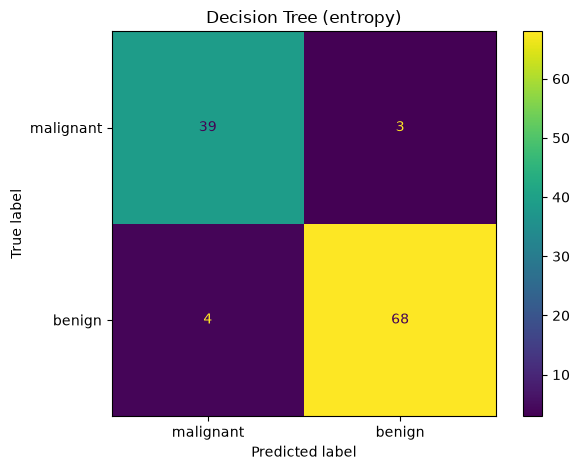

In [13]:

for criterion, model in decision_tree_models.items():
    show_confusion_matrix(
        model,
        X_test,
        y_test,
        f"Decision Tree ({criterion})"
    )


In [14]:

display(
    decision_tree_results_df[
        ["Model", "Accuracy", "Precision", "Recall", "F1-score"]
    ].round(3)
)


,Model,Accuracy,Precision,Recall,F1-score
0,Decision Tree (gini),0.939,0.958,0.944,0.951
1,Decision Tree (entropy),0.939,0.958,0.944,0.951



## Q1(c): Logistic Regression and Regularization

**Aim:** To implement Logistic Regression, demonstrate the sigmoid function, visualize a decision boundary, and compare L1 and L2 regularization.

**Theory:**
Logistic Regression estimates the probability of a class using the sigmoid function:

sigmoid(z) = 1 / (1 + exp(-z))

For binary classification, a probability threshold of 0.5 is commonly used to determine the predicted class.

L1 regularization can shrink coefficients to zero, while L2 regularization penalizes large squared coefficients.


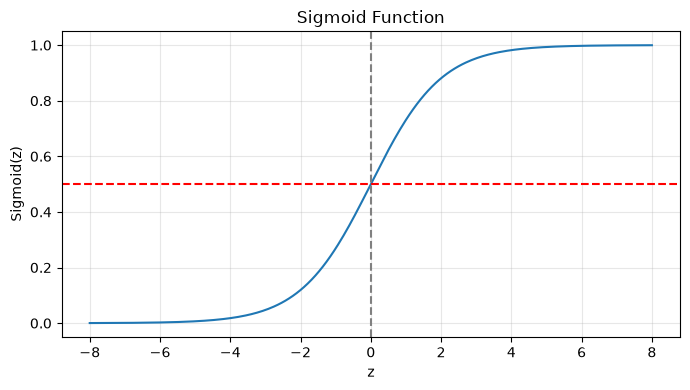

In [15]:

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))


z = np.linspace(-8, 8, 300)
probabilities = sigmoid(z)

plt.figure(figsize=(7, 4))
plt.plot(z, probabilities)
plt.axhline(0.5, linestyle="--", color="red")
plt.axvline(0, linestyle="--", color="gray")

plt.xlabel("z")
plt.ylabel("Sigmoid(z)")
plt.title("Sigmoid Function")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [16]:
#Comparing Logistic Regression with L1 and L2 regularization
logistic_models = {
    "Logistic Regression (L2)": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l2",
            C=1.0,
            max_iter=5000,
            random_state=RANDOM_STATE
        )
    ),
    "Logistic Regression (L1)": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l1",
            solver="liblinear",
            C=1.0,
            max_iter=5000,
            random_state=RANDOM_STATE
        )
    )
}

logistic_results = []
logistic_predictions = {}

for name, model in logistic_models.items():
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    logistic_predictions[name] = predictions

    logistic_results.append(
        evaluate_classification(
            y_test,
            predictions,
            name,
            probabilities
        )
    )

logistic_results_df = pd.DataFrame(logistic_results)

display(logistic_results_df.round(3))


c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Admin\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression (L2),0.982,0.986,0.986,0.986,0.995
1,Logistic Regression (L1),0.991,0.986,1.000,0.993,0.997


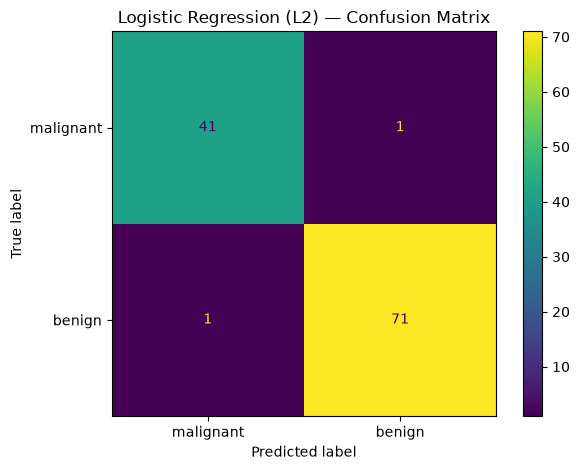

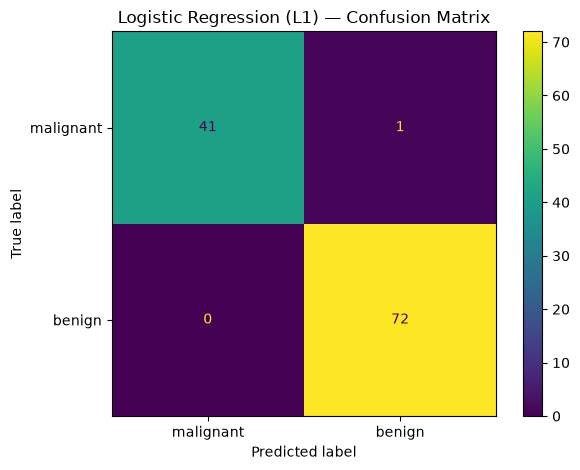

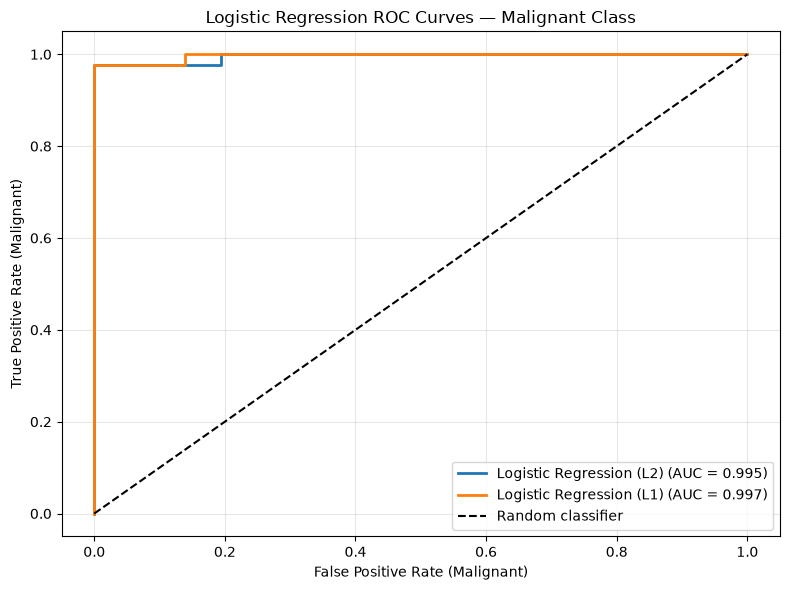

In [ ]:
# Compare confusion matrices and ROC curves for Logistic Regression models

from sklearn.metrics import roc_curve, roc_auc_score

# 1. Confusion matrices
for name, model in logistic_models.items():
    show_confusion_matrix(
        model,
        X_test,
        y_test,
        f"{name} — Confusion Matrix"
    )

# 2. ROC curves
plt.figure(figsize=(8, 6))

# In the Breast Cancer dataset:
# 0 = Malignant, 1 = Benign
# We treat Malignant (class 0) as the positive class.

for name, model in logistic_models.items():

    # Probability of malignant class (class 0)
    probabilities = model.predict_proba(X_test)[:, 0]

    fpr, tpr, thresholds = roc_curve(
        y_test,
        probabilities,
        pos_label=0
    )

    auc = roc_auc_score(
        (y_test == 0).astype(int),
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc:.3f})"
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate (Malignant)")
plt.ylabel("True Positive Rate (Malignant)")
plt.title("Logistic Regression ROC Curves — Malignant Class")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


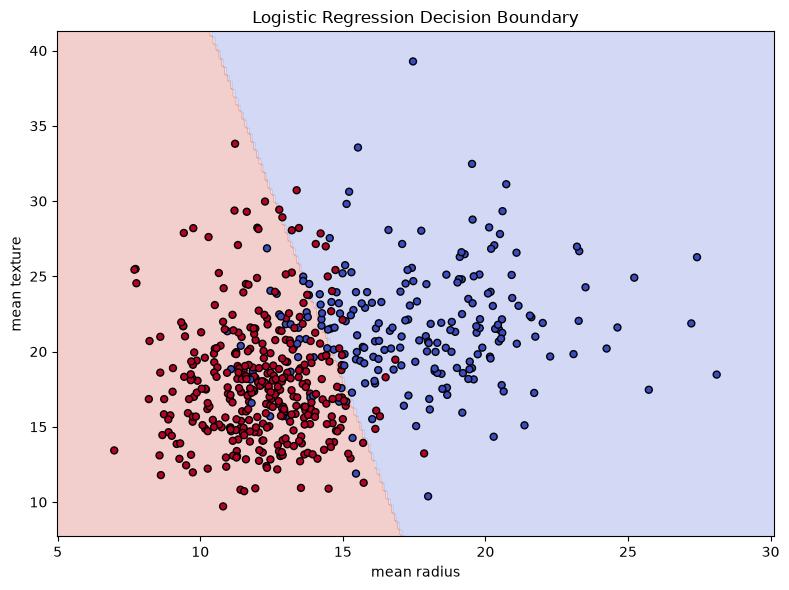

Accuracy using two selected features: 0.877


In [ ]:
#Understanding the decision boundary of Logistic Regression using two features
# Select two features for visualization only.
feature_names_2d = [
    "mean radius",
    "mean texture"
]

X_2d = X_cls[feature_names_2d]

X_2d_train, X_2d_test, y_2d_train, y_2d_test = train_test_split(
    X_2d,
    y_cls,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_cls
)

boundary_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
)

boundary_model.fit(X_2d_train, y_2d_train)

x_min, x_max = X_2d.iloc[:, 0].min() - 2, X_2d.iloc[:, 0].max() + 2
y_min, y_max = X_2d.iloc[:, 1].min() - 2, X_2d.iloc[:, 1].max() + 2

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid = pd.DataFrame(
    np.c_[xx.ravel(), yy.ravel()],
    columns=feature_names_2d
)

grid_predictions = boundary_model.predict(grid).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, grid_predictions, alpha=0.25, cmap="coolwarm")
plt.scatter(
    X_2d.iloc[:, 0],
    X_2d.iloc[:, 1],
    c=y_cls,
    cmap="coolwarm",
    edgecolors="black",
    s=25
)

plt.xlabel(feature_names_2d[0])
plt.ylabel(feature_names_2d[1])
plt.title("Logistic Regression Decision Boundary")
plt.tight_layout()
plt.show()

print(
    "Accuracy using two selected features:",
    round(
        accuracy_score(
            y_2d_test,
            boundary_model.predict(X_2d_test)
        ),
        3
    )
)


### Inference

The ROC curves demonstrate that both L1- and L2-regularized Logistic Regression models achieve excellent classification performance, with AUC values of 0.997 and 0.995, respectively. These values indicate a strong ability to distinguish between malignant and benign tumors across different classification thresholds, with L1 regularization performing marginally better. The decision boundary visualization shows how Logistic Regression separates the two classes using mean radius and mean texture. The approximately linear boundary is consistent with the model's linear decision function, while some overlap between observations near the boundary indicates that these two features alone cannot perfectly separate the classes. Overall, the results demonstrate the effectiveness of Logistic Regression for this classification problem, with the ROC curves evaluating models trained on all 30 features and the decision boundary illustrating classification using only two features.


## Q1(d): K-Nearest Neighbors (KNN)

**Aim:** To implement KNN classification and study the effect of different values of K.

**Theory:**
KNN classifies a new observation using the majority class among its K nearest training observations. Distance is commonly calculated using Euclidean distance.

Feature scaling is important because features with large numerical ranges can otherwise dominate the distance calculation.


In [20]:

knn_models = {}
knn_results = []

for k in [3, 5, 7, 9, 11]:
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    knn_models[k] = model

    knn_results.append(
        evaluate_classification(
            y_test,
            predictions,
            f"KNN (K={k})",
            probabilities
        )
    )

knn_results_df = pd.DataFrame(knn_results)

display(knn_results_df.round(3))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,KNN (K=3),0.982,0.973,1.000,0.986,0.983
1,KNN (K=5),0.956,0.959,0.972,0.966,0.979
2,KNN (K=7),0.974,0.960,1.000,0.980,0.988
3,KNN (K=9),0.974,0.960,1.000,0.980,0.994
4,KNN (K=11),0.974,0.960,1.000,0.980,0.991


In [21]:

knn_models = {}
knn_results = []

for k in [3, 5, 7, 9, 11]:
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    knn_models[k] = model

    knn_results.append(
        evaluate_classification(
            y_test,
            predictions,
            f"KNN (K={k})",
            probabilities
        )
    )

knn_results_df = pd.DataFrame(knn_results)

display(knn_results_df.round(3))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,KNN (K=3),0.982,0.973,1.000,0.986,0.983
1,KNN (K=5),0.956,0.959,0.972,0.966,0.979
2,KNN (K=7),0.974,0.960,1.000,0.980,0.988
3,KNN (K=9),0.974,0.960,1.000,0.980,0.994
4,KNN (K=11),0.974,0.960,1.000,0.980,0.991


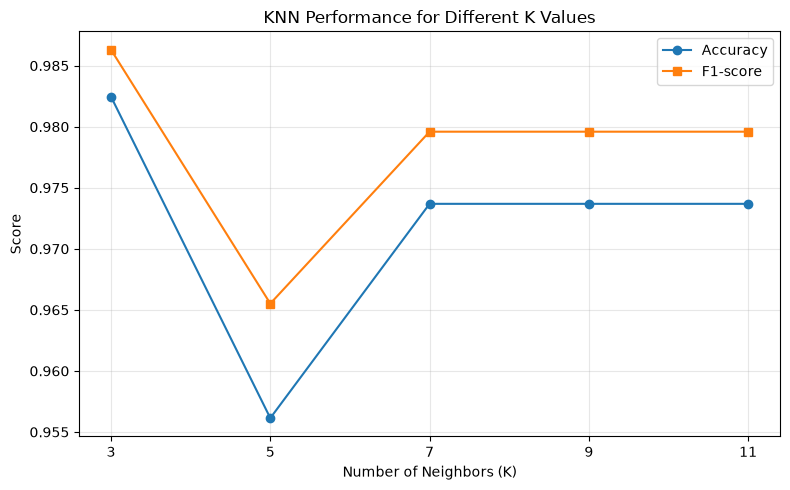

In [22]:

plt.figure(figsize=(8, 5))

plt.plot(
    [3, 5, 7, 9, 11],
    knn_results_df["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    [3, 5, 7, 9, 11],
    knn_results_df["F1-score"],
    marker="s",
    label="F1-score"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Score")
plt.title("KNN Performance for Different K Values")
plt.xticks([3, 5, 7, 9, 11])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Best K by test F1-score: 3


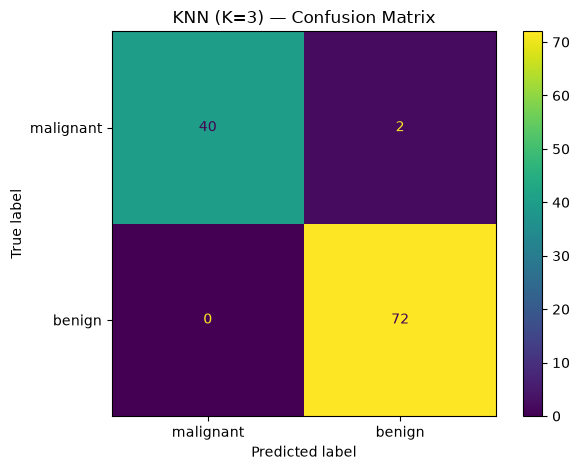

In [23]:

best_knn_row = knn_results_df.sort_values(
    "F1-score",
    ascending=False
).iloc[0]

best_k = int(best_knn_row["Model"].split("=")[1].replace(")", ""))

print("Best K by test F1-score:", best_k)

show_confusion_matrix(
    knn_models[best_k],
    X_test,
    y_test,
    f"KNN (K={best_k}) — Confusion Matrix"
)


### Inference

The KNN classifier was evaluated using different values of K (3, 5, 7, 9, and 11). KNN with K = 3 achieved the highest accuracy of 98.2% and the highest F1-score of 0.986, indicating an excellent balance between precision and recall. It also achieved a recall of 1.000, meaning that all actual positive cases were correctly identified on the test set. KNN with K = 7, 9, and 11 also achieved a recall of 1.000, while K = 5 produced comparatively lower performance. Overall, K = 3 performed best in terms of accuracy, precision, and F1-score, whereas K = 9 achieved the highest ROC-AUC of 0.994. These results demonstrate that the choice of K influences classification performance, and K = 3 was the best option based on the F1-score and accuracy for this test split.


## Q1(e): Gaussian Naive Bayes Classification

**Aim:** To implement Gaussian Naive Bayes and evaluate its classification performance.

**Theory:**
Naive Bayes uses Bayes' theorem to estimate the probability of a class given the input features. It assumes that features are conditionally independent given the class.

Gaussian Naive Bayes models each feature within a class using a Gaussian distribution.


In [24]:

naive_bayes_model = GaussianNB()

naive_bayes_model.fit(X_train, y_train)

nb_predictions = naive_bayes_model.predict(X_test)
nb_probabilities = naive_bayes_model.predict_proba(X_test)[:, 1]

naive_bayes_results_df = pd.DataFrame([
    evaluate_classification(
        y_test,
        nb_predictions,
        "Gaussian Naive Bayes",
        nb_probabilities
    )
])

display(naive_bayes_results_df.round(3))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Gaussian Naive Bayes,0.939,0.945,0.958,0.952,0.988


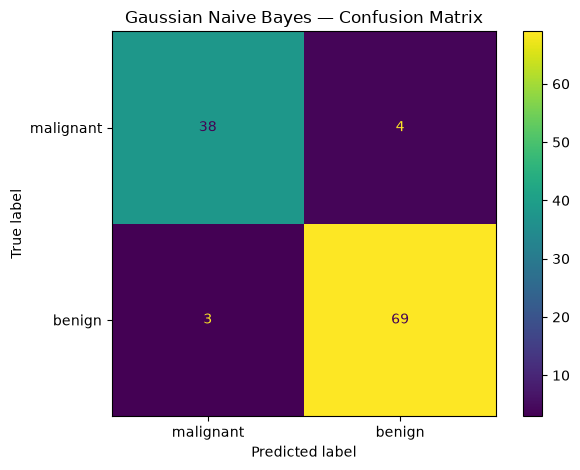

              precision    recall  f1-score   support

   malignant       0.93      0.90      0.92        42
      benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



In [25]:

show_confusion_matrix(
    naive_bayes_model,
    X_test,
    y_test,
    "Gaussian Naive Bayes — Confusion Matrix"
)

print(
    classification_report(
        y_test,
        nb_predictions,
        target_names=cancer.target_names,
        zero_division=0
    )
)


### Inference

The Gaussian Naive Bayes classifier achieved an overall accuracy of approximately 94% on the test dataset. The confusion matrix shows that 38 malignant cases and 69 benign cases were correctly classified, while 4 malignant cases were incorrectly classified as benign and 3 benign cases were incorrectly classified as malignant. The model achieved a precision of 0.93 and a recall of 0.90 for the malignant class, with an F1-score of 0.92. For the benign class, it achieved a precision of 0.95, recall of 0.96 and F1-score of 0.95. These results indicate that the classifier performs well overall, although it failed to identify four malignant cases. Since detecting malignant cases is particularly important in medical classification, improving malignant-class recall would be a valuable objective for further model optimization.


# Q3: Performance Analysis of Supervised Learning Models

The performance of the implemented models is evaluated using suitable metrics.

For regression, MAE and RMSE measure prediction errors, while R² measures the proportion of target variance explained by the model.

For classification, accuracy measures overall correctness, precision measures the correctness of positive predictions, recall measures the proportion of actual positive cases detected, and F1-score balances precision and recall.

ROC-AUC measures the ability to distinguish between classes across different classification thresholds.


In [27]:

# Combine classification results from Q1(b), Q1(c), Q1(d) and Q1(e).

classification_comparison_df = pd.concat(
    [
        decision_tree_results_df,
        logistic_results_df,
        knn_results_df,
        naive_bayes_results_df
    ],
    ignore_index=True
)

classification_comparison_df = classification_comparison_df.sort_values(
    "F1-score",
    ascending=False
).reset_index(drop=True)

print("CLASSIFICATION MODEL COMPARISON")
display(classification_comparison_df.round(3))

print("\nREGRESSION MODEL COMPARISON")
display(regression_results_df.round(3))


CLASSIFICATION MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression (L1),0.991,0.986,1.000,0.993,0.997
1,KNN (K=3),0.982,0.973,1.000,0.986,0.983
2,Logistic Regression (L2),0.982,0.986,0.986,0.986,0.995
3,KNN (K=9),0.974,0.960,1.000,0.980,0.994
4,KNN (K=11),0.974,0.960,1.000,0.980,0.991
5,KNN (K=7),0.974,0.960,1.000,0.980,0.988
6,KNN (K=5),0.956,0.959,0.972,0.966,0.979
7,Gaussian Naive Bayes,0.939,0.945,0.958,0.952,0.988
8,Decision Tree (entropy),0.939,0.958,0.944,0.951,NaN
9,Decision Tree (gini),0.939,0.958,0.944,0.951,NaN



REGRESSION MODEL COMPARISON


,Model,MAE,RMSE,R2
0,Linear Regression,42.794,53.853,0.453
1,Ridge Regression,42.812,53.777,0.454
2,Lasso Regression,42.805,53.709,0.456


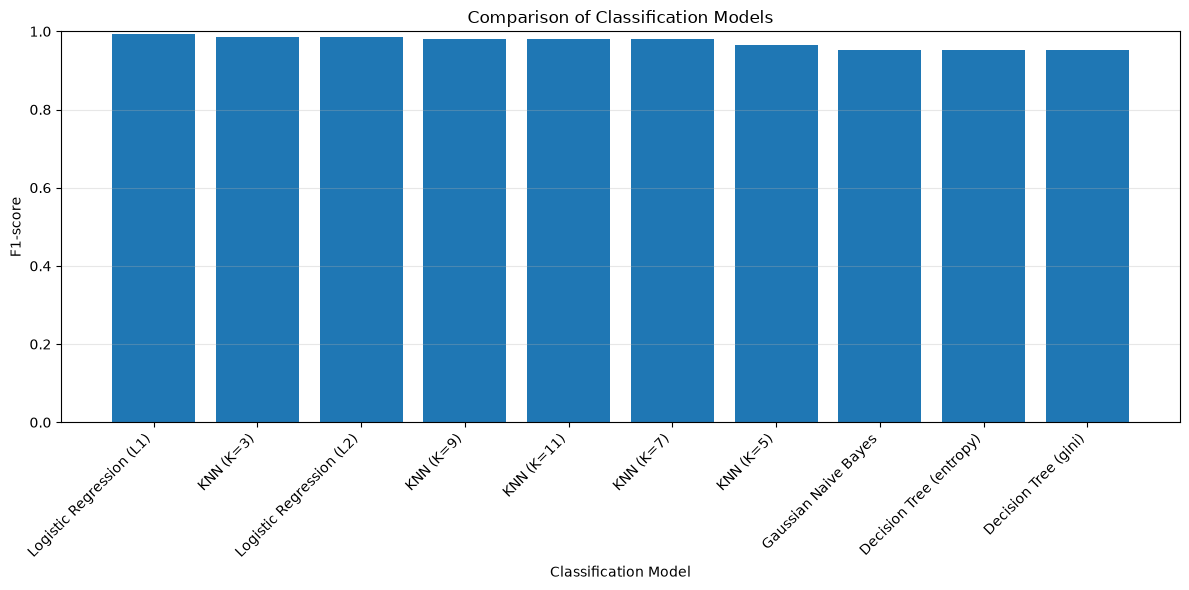

In [28]:

plt.figure(figsize=(12, 6))

plt.bar(
    classification_comparison_df["Model"],
    classification_comparison_df["F1-score"]
)

plt.ylabel("F1-score")
plt.xlabel("Classification Model")
plt.title("Comparison of Classification Models")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


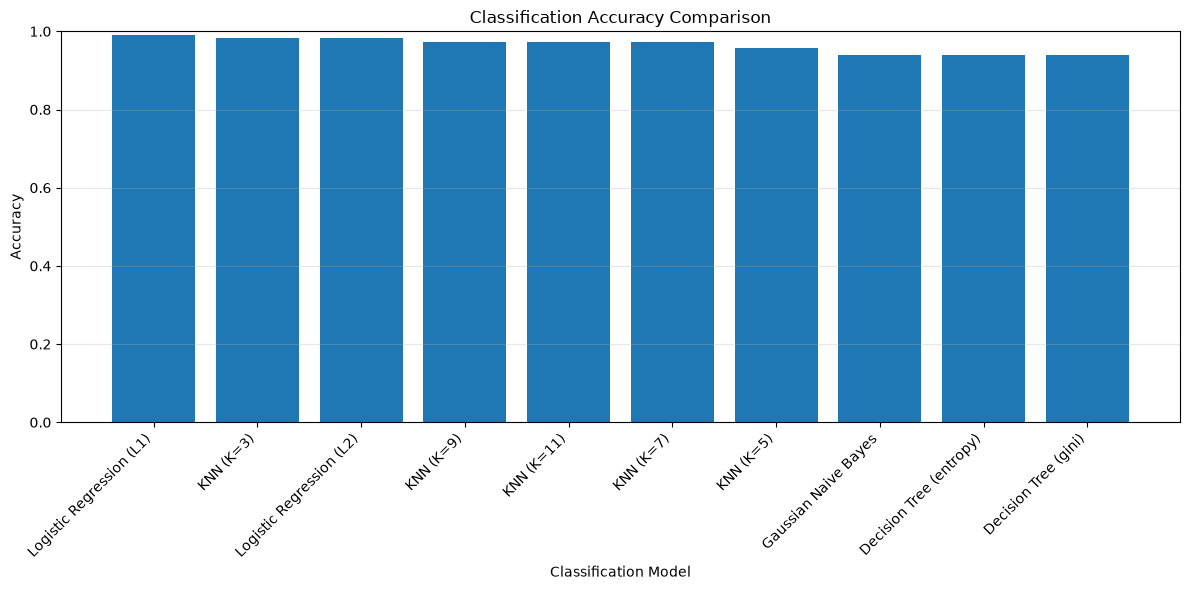

In [29]:

plt.figure(figsize=(12, 6))

plt.bar(
    classification_comparison_df["Model"],
    classification_comparison_df["Accuracy"]
)

plt.ylabel("Accuracy")
plt.xlabel("Classification Model")
plt.title("Classification Accuracy Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [30]:

best_regression_model = regression_results_df.loc[
    regression_results_df["RMSE"].idxmin()
]

best_classification_model = classification_comparison_df.loc[
    classification_comparison_df["F1-score"].idxmax()
]

print("BEST REGRESSION MODEL — based on test RMSE")
print("Model:", best_regression_model["Model"])
print("MAE:", round(best_regression_model["MAE"], 3))
print("RMSE:", round(best_regression_model["RMSE"], 3))
print("R2:", round(best_regression_model["R2"], 3))

print("\nBEST CLASSIFICATION MODEL — based on test F1-score")
print("Model:", best_classification_model["Model"])
print("Accuracy:", round(best_classification_model["Accuracy"], 3))
print("Precision:", round(best_classification_model["Precision"], 3))
print("Recall:", round(best_classification_model["Recall"], 3))
print("F1-score:", round(best_classification_model["F1-score"], 3))


BEST REGRESSION MODEL — based on test RMSE
Model: Lasso Regression
MAE: 42.805
RMSE: 53.709
R2: 0.456

BEST CLASSIFICATION MODEL — based on test F1-score
Model: Logistic Regression (L1)
Accuracy: 0.991
Precision: 0.986
Recall: 1.0
F1-score: 0.993



## Conclusion

The supervised learning algorithms were implemented and evaluated using regression and classification datasets.

Linear Regression, Ridge and Lasso were compared using MAE, RMSE and R². Decision Tree classification was evaluated using Gini impurity and entropy. Logistic Regression was studied using the sigmoid function, regularization and a visualized decision boundary. KNN was evaluated for different values of K, and Gaussian Naive Bayes was implemented using its conditional independence assumption.

The classification models were compared using accuracy, precision, recall, F1-score and ROC-AUC where available. The best-performing models were identified using the recorded test results.

The experiments demonstrate that model performance depends on the dataset, algorithm, parameter settings and evaluation metric. No single algorithm is guaranteed to perform best on every problem.
